In [21]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

In [22]:

# Load the prepared data
X_train = pd.read_csv("../../data/processed/X_train_processed.csv")
X_test = pd.read_csv("../../data/processed/X_test_processed.csv")
y_train = pd.read_csv("../../data/processed/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../../data/processed/y_test.csv").squeeze("columns")


In [23]:

# Create the SVM model
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    class_weight="balanced",
    probability=True,
    random_state=42
)


In [24]:

# Train the model
svm_model.fit(X_train, y_train)

# Predict the test labels
y_pred = svm_model.predict(X_test)

# Get bad-risk scores
y_train_score = svm_model.predict_proba(X_train)[:, 1]
y_test_score = svm_model.predict_proba(X_test)[:, 1]


c:\Users\Ayush\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [25]:
# Calculate ROC curves
train_fpr, train_tpr, _ = roc_curve(y_train, y_train_score)
test_fpr, test_tpr, _ = roc_curve(y_test, y_test_score)

In [26]:
# Calculate ROC-AUC scores
train_auc = roc_auc_score(y_train, y_train_score)
test_auc = roc_auc_score(y_test, y_test_score)

In [27]:
# Show evaluation results
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred, zero_division=0))
print("ROC-AUC:", test_auc)

Accuracy: 0.6282722513089005

Confusion matrix:
 [[87 46]
 [25 33]]

Classification report:
               precision    recall  f1-score   support

           0       0.78      0.65      0.71       133
           1       0.42      0.57      0.48        58

    accuracy                           0.63       191
   macro avg       0.60      0.61      0.60       191
weighted avg       0.67      0.63      0.64       191

ROC-AUC: 0.6720248898107337


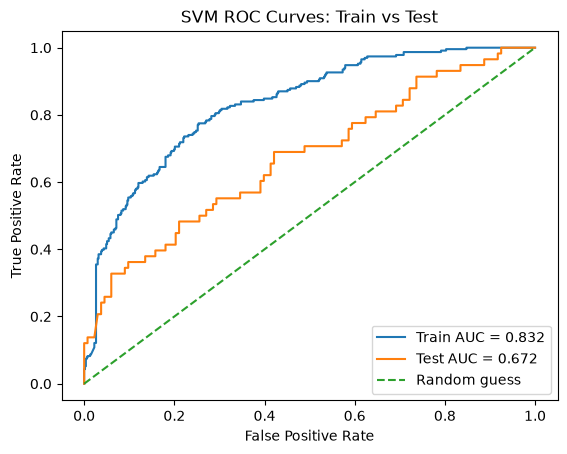

In [28]:
# Plot both curves
plt.plot(train_fpr, train_tpr, label=f"Train AUC = {train_auc:.3f}")
plt.plot(test_fpr, test_tpr, label=f"Test AUC = {test_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SVM ROC Curves: Train vs Test")
plt.legend()

plt.savefig("../../reports/figures/svm_roc_curves.png", dpi=300, bbox_inches="tight")

plt.show()



In [29]:
# Show the score difference
print("Train ROC-AUC:", round(train_auc, 3))
print("Test ROC-AUC:", round(test_auc, 3))
print("Train-test AUC difference:", round(train_auc - test_auc, 3))

Train ROC-AUC: 0.832
Test ROC-AUC: 0.672
Train-test AUC difference: 0.16
